In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

In [3]:
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/'
       'master/cohorts/2026/data/course_lead_scoring_2026.csv')

In [4]:
df

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1
...,...,...,...,...,...,...,...,...,...
4995,organic_search,education,employed,asia,45834.0,2,2,0.37,1
4996,NaN,technology,employed,north_america,84831.0,2,5,0.51,0
4997,organic_search,finance,employed,asia,53636.0,4,6,0.75,1
4998,referral,technology,employed,africa,69430.0,4,8,0.79,1


In [5]:
print(df.isnull().sum())

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64


In [6]:
target = 'converted'
numerical = [c for c in df.columns if df[c].dtype != 'object' and c != target]
categorical = [c for c in df.columns if df[c].dtype == 'object']

In [7]:
df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

In [9]:
df[numerical]

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score
0,organic_search,technology,employed,europe,88160.0,3,4,0.64
1,social_media,technology,employed,south_america,72688.0,3,7,0.72
2,referral,retail,employed,europe,44697.0,3,4,0.58
3,paid_ads,manufacturing,student,0.0,0.0,3,6,0.57
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62
...,...,...,...,...,...,...,...,...
4995,organic_search,education,employed,asia,45834.0,2,2,0.37
4996,0.0,technology,employed,north_america,84831.0,2,5,0.51
4997,organic_search,finance,employed,asia,53636.0,4,6,0.75
4998,referral,technology,employed,africa,69430.0,4,8,0.79


In [10]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [11]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [12]:
y_train = df_train[target].values
y_val = df_val[target].values
y_test = df_test[target].values

In [13]:
for c in ['lead_score', 'number_of_courses_viewed', 'interaction_count', 'annual_income']:
    auc = roc_auc_score(y_train, df_train[c])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[c])   
    print(f'{c:28s} {auc:.4f}')

lead_score                   0.7882
number_of_courses_viewed     0.7230
interaction_count            0.7649
annual_income                0.6082


In [14]:
def train(df_tr, y_tr, C=1.0):
    dicts = df_tr[categorical + numerical].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(dicts)
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, y_tr)
    return dv, model

In [15]:
def predict(df_, dv, model):
    dicts = df_[categorical + numerical].to_dict(orient='records')
    X = dv.transform(dicts)
    return model.predict_proba(X)[:, 1]

In [16]:
dv, model = train(df_train, y_train)
y_pred = predict(df_val, dv, model)
print(round(roc_auc_score(y_val, y_pred), 3))

0.732


In [17]:
thresholds = np.arange(0.0, 1.01, 0.01)

In [18]:
thresholds

array([0.  , 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1 ,
       0.11, 0.12, 0.13, 0.14, 0.15, 0.16, 0.17, 0.18, 0.19, 0.2 , 0.21,
       0.22, 0.23, 0.24, 0.25, 0.26, 0.27, 0.28, 0.29, 0.3 , 0.31, 0.32,
       0.33, 0.34, 0.35, 0.36, 0.37, 0.38, 0.39, 0.4 , 0.41, 0.42, 0.43,
       0.44, 0.45, 0.46, 0.47, 0.48, 0.49, 0.5 , 0.51, 0.52, 0.53, 0.54,
       0.55, 0.56, 0.57, 0.58, 0.59, 0.6 , 0.61, 0.62, 0.63, 0.64, 0.65,
       0.66, 0.67, 0.68, 0.69, 0.7 , 0.71, 0.72, 0.73, 0.74, 0.75, 0.76,
       0.77, 0.78, 0.79, 0.8 , 0.81, 0.82, 0.83, 0.84, 0.85, 0.86, 0.87,
       0.88, 0.89, 0.9 , 0.91, 0.92, 0.93, 0.94, 0.95, 0.96, 0.97, 0.98,
       0.99, 1.  ])

In [19]:
rows = []
for t in thresholds:
    pred_pos = (y_pred >= t)
    act_pos = (y_val == 1)
    tp = (pred_pos & act_pos).sum()
    fp = (pred_pos & ~act_pos).sum()
    fn = (~pred_pos & act_pos).sum()
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
    rows.append((round(t, 2), p, r, f1))
df_pr = pd.DataFrame(rows, columns=['threshold', 'precision', 'recall', 'f1'])

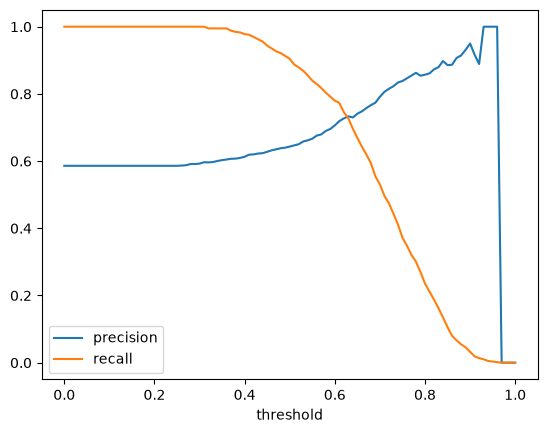

In [20]:
import matplotlib.pyplot as plt
plt.plot(df_pr.threshold, df_pr.precision, label='precision')
plt.plot(df_pr.threshold, df_pr.recall, label='recall')
plt.xlabel('threshold'); plt.legend(); plt.show()

In [21]:
valid = df_pr[(df_pr.precision > 0) | (df_pr.recall > 0)].copy()   # ignore both-zero
valid['diff'] = (valid.precision - valid.recall).abs()
print(valid.loc[valid['diff'].idxmin(), 'threshold'])

0.63


In [22]:
print(df_pr.loc[df_pr.f1.idxmax(), 'threshold'],'| F1 =', round(df_pr.f1.max(), 4))

0.41 | F1 = 0.7576


In [24]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []

In [25]:
for train_idx, val_idx in kfold.split(df_full_train):
    d_tr = df_full_train.iloc[train_idx]
    d_va = df_full_train.iloc[val_idx]
    dv, model = train(d_tr, d_tr[target].values, C=1.0)
    p = predict(d_va, dv, model)
    scores.append(roc_auc_score(d_va[target].values, p))

In [26]:
print(np.round(scores, 4))
print('std:', round(np.std(scores), 3), '| mean:', round(np.mean(scores), 3))

[0.7305 0.7297 0.7363 0.7413 0.721 ]
std: 0.007 | mean: 0.732


In [27]:
for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
        d_tr = df_full_train.iloc[train_idx]
        d_va = df_full_train.iloc[val_idx]
        dv, model = train(d_tr, d_tr[target].values, C=C)
        p = predict(d_va, dv, model)
        scores.append(roc_auc_score(d_va[target].values, p))
    print(f'C={C:<9} mean={np.mean(scores):.3f} std={np.std(scores):.3f}')

C=1e-06     mean=0.617 std=0.019
C=0.001     mean=0.749 std=0.010
C=1         mean=0.732 std=0.007
